# Horizon and a tuned Transformer: where the linear model stops winning on the near-wall signal

Stage 4 showed that on 10-step forecasts a linear autoregressive model fitted by least squares beats every network by two orders of magnitude, because the signal is smooth over 10 samples. Two questions follow, and this notebook answers both on one set of windows.

- **Part (a): where does the linear model stop winning?** The same 300 past values, output windows of 10, 30, 100 and 300 future steps, the same split in time. For each horizon: persistence, the linear autoregressive model (all 300 past values), and a GRU with 32 units and a dense head of the horizon's size, three seeds. Error per future step and over the window, in the normalised units of Stages 2–4, on the same test windows for every horizon.
- **Part (b): the Transformer with a training budget it can use.** The small Transformer of Stage 3 trained with the learning rate the recurrent networks use (1e-3, gradient clipping 1, early stopping with patience 8, up to 100 epochs), against the setting it had there (1e-4, 50 epochs), persistence, the linear model and the GRU of part (a), all at horizon 10.

Every window is built by the loader of Stage 1, so no window straddles two simulation files. Seeds 0, 1 and 2 for every training; seed 0 is the base run. A difference is called an effect only when it is larger than the seed range.

# Stage 5 — Horizon and a tuned Transformer: where the linear model stops winning

**Portfolio project: forecasting a turbulent channel-flow signal with recurrent networks and a Transformer.**

Stage 4 showed that on 10-step forecasts a least-squares linear autoregressive model beats every network by two orders of magnitude, because the signal is smooth over 10 samples. Two questions follow. Part (a): where does the linear model stop winning? I cut one set of windows with 300 past and 300 future values (same stride, same file rule, same split in time as Stages 2–4, so every horizon is scored on the same test windows) and compare persistence, the linear model and a GRU with a dense head of the horizon's size at 10, 30, 100 and 300 steps ahead, three seeds each. Part (b): does the Stage 3 Transformer beat persistence once it gets the training budget the recurrent networks had (learning rate 1e-3, gradient clipping, early stopping, up to 100 epochs) instead of its Stage 3 setting (1e-4, 50 epochs)?

**What it shows.** The GRU never beats the linear model beyond its seed range: the ratio of their errors falls from 73× at 10 steps to 4.8× at 30, 1.3× at 100 and 1.07× at 300, where both approach the error of predicting the mean. The GRU beats persistence at every horizon. The tuned Transformer (0.064, range 0.056–0.070 over three seeds) beats persistence (0.094) beyond the seed range, which the Stage 3 setting never did (0.104), but it stays far from the GRU (0.029) and from the linear model (0.0004) on the same windows.

**How it connects.** It reads `data/utmp_y50_raw_timeseries.h5` (Stage 1) through `cfd_data_tools.py`, takes the normalisation statistics and a persistence check from the Stages 2–4 windows, copies the Transformer builder of Stage 3 unchanged, and reads the device timings and the result table of Stage 4 (the latter only as an earlier run for orientation, since this stage's windows are fewer: 4,345 instead of 7,419).

**About the outputs.** The outputs below come from my single run (Apple M3 Max, Apple GPU, 2026-10-14, 25 minutes, longest training 204 s). Afterwards I changed only text for this repository: this cell and the paths cell, and the path lines (data from `../data/`, Stage 4 tables from `../results/04_horizon_and_baselines/`, tables and figures to `../results/05_horizon_and_tuned_transformer/`, seed-0 models to `../models/05_horizon_and_tuned_transformer/`).

In [ ]:
# Paths in the repository layout (run this notebook from notebooks/)
from pathlib import Path
DATA_FILE = Path("../data/utmp_y50_raw_timeseries.h5")          # the processed signal written by Stage 1
TIMING_DIR = Path("../results/04_horizon_and_baselines")        # device_timing_cpu.csv and device_timing_gpu.csv of Stage 4
EARLIER_STAGE = Path("../results/04_horizon_and_baselines")     # Stage 4's result tables (read only for the comparison)
RES = Path("../results/05_horizon_and_tuned_transformer"); RES.mkdir(parents=True, exist_ok=True)
MOD = Path("../models/05_horizon_and_tuned_transformer"); MOD.mkdir(parents=True, exist_ok=True)
print("signal present:", DATA_FILE.exists(), "| timings present:", (TIMING_DIR / "device_timing_gpu.csv").exists(),
      "| earlier-stage tables present:", (EARLIER_STAGE / "b_cost_vs_error.csv").exists())

In [2]:
import json, time, platform
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from cfd_data_tools import CFDTimeSeriesLoader

print("TensorFlow", tf.__version__, "| Keras", tf.keras.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"), "|", platform.machine())

# Device per network from the step timing of Stage 4 (the environment is unchanged since then):
# median of 30 training steps inside model.fit after 10 warm-up steps, batch 64, window 300.
timing = pd.concat([pd.read_csv(TIMING_DIR / "device_timing_cpu.csv"), pd.read_csv(TIMING_DIR / "device_timing_gpu.csv")])
timing_tab = timing.pivot(index="network", columns="device", values="median_ms")
print(timing_tab.loc[["GRU", "Simple Transformer"]].round(2))
NET_DEVICE = {"GRU": "/GPU:0", "Simple Transformer": "/GPU:0"}
for k, v in NET_DEVICE.items():
    faster = "/CPU:0" if timing_tab.loc[k, "cpu"] < timing_tab.loc[k, "gpu"] else "/GPU:0"
    assert faster == v, (k, faster, v)
print("Device per network:", NET_DEVICE)
T_START = time.time()

TensorFlow 2.18.1 | Keras 3.6.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | arm64
device                 cpu    gpu
network                          
GRU                  35.49  17.73
Simple Transformer  126.53  53.15
Device per network: {'GRU': '/GPU:0', 'Simple Transformer': '/GPU:0'}


## One set of windows for every horizon

Stages 2–4 cut windows of 300 past values and 10 future values with a stride of 10, inside one simulation file each, and split them 70 % / 15 % / 15 % in time order. Here I cut windows of 300 past values and **300 future values** with the same stride and the same file rule, split them the same way, and read the shorter horizons as the first 10, 30 or 100 of the 300 future values. So every horizon is scored on exactly the same test windows, with the same inputs; the split falls at the same point in time as in Stages 2–4 (the windows of each file are equally many, so the 70 % boundary sits in the same file).

The longer windows fit fewer times into each 1,000-sample file (41 instead of 70), so there are fewer windows than before. The normalisation is the one of Stages 2–4: the mean and standard deviation of their training inputs, so all errors are in the same units as there. I load their windows once to take those two numbers and to check that persistence gives the same error as before.

In [3]:
loader = CFDTimeSeriesLoader(processed_dir=str(DATA_FILE.parent), y_index=50, variable="utmp")
loader.load_processed_h5(str(DATA_FILE))

# Stages 2–4' call: only the normalisation statistics and a persistence check are taken from it
earlier = loader.prepare_forecasting_data(input_window=300, output_window=10, stride=10, batch_size=64)
MU, SIGMA = float(earlier["signal_mean"]), float(earlier["signal_std"])
pers_earlier = float(np.mean(np.abs(earlier["y_test"] - np.repeat(earlier["X_test"][:, -1, :], 10, axis=1))))
print(f"Stages 2–4: {len(earlier['X_train'])} / {len(earlier['X_val'])} / {len(earlier['X_test'])} windows; mean {MU:.6f}, std {SIGMA:.6f}; "
      f"persistence test MAE at horizon 10 = {pers_earlier:.7f}")

# This notebook's windows: 300 past, 300 future, stride 10, inside one file (the loader's own rule)
H_MAX = 300
X_all, y_all = loader.create_forecasting_windows(input_window=300, output_window=H_MAX, stride=10)
Xtr_r, Xva_r, Xte_r, ytr_r, yva_r, yte_r = loader.split_train_val_test(X_all, y_all, train_fraction=0.70, val_fraction=0.15)
norm = lambda a: ((a - MU) / SIGMA).astype("float32")
Xtr, Xva, Xte, ytr, yva, yte = map(norm, (Xtr_r, Xva_r, Xte_r, ytr_r, yva_r, yte_r))
print("this notebook:", "train", Xtr.shape, ytr.shape, "| val", Xva.shape, "| test", Xte.shape)
print(f"mean and std of this notebook's training inputs (for the record, not used): {Xtr_r.mean():.6f}, {Xtr_r.std():.6f}")

# Where the split falls in time (sample index of the first window of each part)
starts = [s for s in range(0, len(loader.all_signal) - 600, 10)
          if loader.all_file_indices[s] == loader.all_file_indices[s + 599]]
n_tr, n_va = len(Xtr), len(Xva)
print(f"first training / validation / test window starts at sample {starts[0]} / {starts[n_tr]} / {starts[n_tr + n_va]} "
      f"(file {loader.all_file_indices[starts[n_tr]]} / {loader.all_file_indices[starts[n_tr + n_va]]}); "
      f"Stages 2–4: validation from window {len(earlier['X_train'])} of 7,419, i.e. sample {int(len(earlier['X_train']) / 7419 * 106000)} by proportion")
HORIZONS = (10, 30, 100, 300)

Processed HDF5 loaded from:
../data/utmp_y50_raw_timeseries.h5

Loaded arrays:
all_signal: (106000,)
all_timev: (106000,)
all_file_indices: (106000,)
Forecasting windows created:
X: (7419, 300, 1)
y: (7419, 10)
Normalization statistics:
signal_mean: 0.9274324
signal_std: 0.10147347
Stages 2–4: 5193 / 1112 / 1114 windows; mean 0.927432, std 0.101473; persistence test MAE at horizon 10 = 0.1027811
Forecasting windows created:
X: (4345, 300, 1)
y: (4345, 300)
this notebook: train (3041, 300, 1) (3041, 300) | val (651, 300, 1) | test (653, 300, 1)
mean and std of this notebook's training inputs (for the record, not used): 0.924226, 0.101250
first training / validation / test window starts at sample 0 / 74070 / 90020 (file 74 / 90); Stages 2–4: validation from window 5193 of 7,419, i.e. sample 74195 by proportion


2026-10-14 20:21:40.609287: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3 Max
2026-10-14 20:21:40.609313: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 48.00 GB
2026-10-14 20:21:40.609319: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 18.72 GB
I0000 00:00:1792023700.609331 57422845 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1792023700.609349 57422845 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


## The two references at every horizon

**Persistence**: every future value equals the last input value. **Linear autoregressive model**: each future value is a weighted sum of the 300 past values plus a constant, `y = [x, 1] W`, with `W` (301 × h) fitted by ordinary least squares on the training windows only; no hyperparameter, so the validation windows are unused. Both are scored per future step (mean absolute error over the test windows) and over the window (mean of the per-step errors). I also keep the root-mean-square error per step for the record.

In [4]:
def mae_steps(y, p): return np.mean(np.abs(y - p), axis=0)
def rmse_steps(y, p): return np.sqrt(np.mean((y - p) ** 2, axis=0))

A_tr = np.hstack([Xtr[:, :, 0], np.ones((len(Xtr), 1), dtype="float32")]).astype("float64")
A_te = np.hstack([Xte[:, :, 0], np.ones((len(Xte), 1), dtype="float32")]).astype("float64")
t0 = time.perf_counter()
W_all, *_ = np.linalg.lstsq(A_tr, ytr.astype("float64"), rcond=None)   # one fit gives W for every horizon (columns are independent)
lin_fit_s = time.perf_counter() - t0
lin_pred = A_te @ W_all
pers_pred = np.repeat(Xte[:, -1, :], H_MAX, axis=1)

ref_steps = []
for name, p in (("persistence", pers_pred), ("linear AR", lin_pred)):
    for s in range(H_MAX):
        ref_steps.append(dict(model=name, step=s + 1, mae=float(np.mean(np.abs(yte[:, s] - p[:, s]))), rmse=float(np.sqrt(np.mean((yte[:, s] - p[:, s]) ** 2)))))
ref_steps = pd.DataFrame(ref_steps); ref_steps.to_csv(RES / "a_reference_by_step.csv", index=False)
ref_window = pd.DataFrame([dict(model=name, horizon=h, mae=float(ref_steps[(ref_steps.model == name) & (ref_steps.step <= h)].mae.mean()),
                                rmse=float(np.sqrt((ref_steps[(ref_steps.model == name) & (ref_steps.step <= h)].rmse ** 2).mean())))
                           for name in ("persistence", "linear AR") for h in HORIZONS])
print(f"linear AR: {W_all.shape[0]} coefficients per future step, {W_all.size:,} in total, fitted in {lin_fit_s * 1000:.0f} ms; "
      f"condition number of the design matrix {np.linalg.cond(A_tr):.3g}")
print(ref_window.pivot(index="horizon", columns="model", values="mae").round(5).rename(columns=lambda c: f"{c} (MAE over window)"))

linear AR: 301 coefficients per future step, 90,300 in total, fitted in 48 ms; condition number of the design matrix 2.52e+07
model    linear AR (MAE over window)  persistence (MAE over window)
horizon                                                            
10                           0.00039                        0.09413
30                           0.03513                        0.24109
100                          0.38579                        0.55217
300                          0.68378                        0.87123


## The GRU at every horizon

One GRU layer with 32 units, then a dense layer with as many outputs as the horizon, so the whole future window is predicted at once from one hidden state (the same network as in Stage 4, with a wider head). Adam at learning rate 1e-3, mean-squared-error loss, batch 64, early stopping on the validation loss with patience 8 (best weights restored), up to 100 epochs; no learning-rate schedule. The seed sets the initial weights and the training-set shuffle. The GRU trains on the Apple GPU, the faster device for it; note that the GPU's GRU kernel computes a different function from Keras's reference GRU for the same weights (found in Stage 2), so the saved GRU models reproduce their numbers only on an Apple GPU.

In [5]:
def build_gru(h):
    m = tf.keras.Sequential([tf.keras.layers.Input(shape=(300, 1)), tf.keras.layers.GRU(32), tf.keras.layers.Dense(h)], name=f"GRU_h{h}")
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
    return m

def make_ds(X, y, shuffle, seed):
    ds = tf.data.Dataset.from_tensor_slices((X, y)).cache()
    if shuffle: ds = ds.shuffle(len(X), seed=seed)
    return ds.batch(64).prefetch(tf.data.AUTOTUNE)

def fit_model(m, ytr_h, yva_h, seed, epochs, callbacks, device):
    with tf.device(device):
        t0 = time.perf_counter()
        hist = m.fit(make_ds(Xtr, ytr_h, True, seed), validation_data=make_ds(Xva, yva_h, False, seed), epochs=epochs, verbose=0, callbacks=callbacks)
        train_s = time.perf_counter() - t0
        p = m.predict(Xte, verbose=0, batch_size=256)
    return hist, train_s, p

a_runs, a_steps = [], []
def run_gru_seed(seed):
    for h in HORIZONS:
        tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
        m = build_gru(h)
        hist, train_s, p = fit_model(m, ytr[:, :h], yva[:, :h], seed, 100,
                                     [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)], NET_DEVICE["GRU"])
        e = mae_steps(yte[:, :h], p); r = rmse_steps(yte[:, :h], p)
        a_runs.append(dict(model="GRU", horizon=h, seed=seed, device=NET_DEVICE["GRU"], params=m.count_params(), epochs=len(hist.history["loss"]),
                           best_epoch=int(np.argmin(hist.history["val_loss"])) + 1, train_s=round(train_s, 1), test_mae=float(e.mean()), test_rmse=float(np.sqrt((r ** 2).mean()))))
        a_steps.extend(dict(model="GRU", horizon=h, seed=seed, step=s + 1, mae=float(e[s]), rmse=float(r[s])) for s in range(h))
        if seed == 0: m.save(MOD / f"GRU_h{h}_seed0.keras")
        print(a_runs[-1], flush=True)

In [6]:
run_gru_seed(0)  # seed 0, the base run

2026-10-14 20:21:41.070006: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


{'model': 'GRU', 'horizon': 10, 'seed': 0, 'device': '/GPU:0', 'params': 3690, 'epochs': 81, 'best_epoch': 73, 'train_s': 76.5, 'test_mae': 0.030674666166305542, 'test_rmse': 0.05265079438686371}


{'model': 'GRU', 'horizon': 30, 'seed': 0, 'device': '/GPU:0', 'params': 4350, 'epochs': 55, 'best_epoch': 47, 'train_s': 51.1, 'test_mae': 0.16543878614902496, 'test_rmse': 0.2831941545009613}


{'model': 'GRU', 'horizon': 100, 'seed': 0, 'device': '/GPU:0', 'params': 6660, 'epochs': 28, 'best_epoch': 20, 'train_s': 27.7, 'test_mae': 0.5028061866760254, 'test_rmse': 0.7022013068199158}


{'model': 'GRU', 'horizon': 300, 'seed': 0, 'device': '/GPU:0', 'params': 13260, 'epochs': 31, 'best_epoch': 23, 'train_s': 29.6, 'test_mae': 0.7306374311447144, 'test_rmse': 0.9565964341163635}


In [7]:
run_gru_seed(1)  # seed 1

{'model': 'GRU', 'horizon': 10, 'seed': 1, 'device': '/GPU:0', 'params': 3690, 'epochs': 75, 'best_epoch': 67, 'train_s': 71.4, 'test_mae': 0.026772379875183105, 'test_rmse': 0.049147650599479675}


{'model': 'GRU', 'horizon': 30, 'seed': 1, 'device': '/GPU:0', 'params': 4350, 'epochs': 68, 'best_epoch': 60, 'train_s': 87.3, 'test_mae': 0.17225617170333862, 'test_rmse': 0.28337839245796204}


{'model': 'GRU', 'horizon': 100, 'seed': 1, 'device': '/GPU:0', 'params': 6660, 'epochs': 35, 'best_epoch': 27, 'train_s': 49.2, 'test_mae': 0.5021074414253235, 'test_rmse': 0.707534909248352}


{'model': 'GRU', 'horizon': 300, 'seed': 1, 'device': '/GPU:0', 'params': 13260, 'epochs': 35, 'best_epoch': 27, 'train_s': 33.0, 'test_mae': 0.7308928370475769, 'test_rmse': 0.9572082757949829}


In [8]:
run_gru_seed(2)  # seed 2

{'model': 'GRU', 'horizon': 10, 'seed': 2, 'device': '/GPU:0', 'params': 3690, 'epochs': 73, 'best_epoch': 65, 'train_s': 69.5, 'test_mae': 0.029268240556120872, 'test_rmse': 0.053912464529275894}


{'model': 'GRU', 'horizon': 30, 'seed': 2, 'device': '/GPU:0', 'params': 4350, 'epochs': 64, 'best_epoch': 56, 'train_s': 60.9, 'test_mae': 0.16426284611225128, 'test_rmse': 0.27569249272346497}


{'model': 'GRU', 'horizon': 100, 'seed': 2, 'device': '/GPU:0', 'params': 6660, 'epochs': 26, 'best_epoch': 18, 'train_s': 25.0, 'test_mae': 0.4989562928676605, 'test_rmse': 0.7023294568061829}


{'model': 'GRU', 'horizon': 300, 'seed': 2, 'device': '/GPU:0', 'params': 13260, 'epochs': 28, 'best_epoch': 20, 'train_s': 26.7, 'test_mae': 0.7302795648574829, 'test_rmse': 0.9575293064117432}


## Part (a): error per future step and over the window, at every horizon

The GRU **beats the linear model at a horizon** only when all three of its seeds are below the linear model's window error and its mean improvement is larger than its seed range (maximum minus minimum over the three seeds). The linear model and persistence are deterministic, so they have no spread.

Test MAE over the window (normalised units); GRU as mean and [min, max] of seeds 0, 1, 2
 horizon  persistence  linear_AR  gru_mean  gru_min  gru_max  gru_range  gru_over_linear  gru_beats_linear  gru_beats_persistence  gru_train_s_mean
      10      0.09413    0.00039   0.02891  0.02677  0.03067    0.00390         73.27535             False                   True          72.46667
      30      0.24109    0.03513   0.16732  0.16426  0.17226    0.00799          4.76250             False                   True          66.43333
     100      0.55217    0.38579   0.50129  0.49896  0.50281    0.00385          1.29938             False                   True          33.96667
     300      0.87123    0.68378   0.73060  0.73028  0.73089    0.00061          1.06848             False                   True          29.76667

Result (a): the GRU does not beat the linear model beyond its seed range at any of the four horizons
GRU / linear AR error ratio by horizon: h=10: 73.3×, h=30: 4.8×, h=10

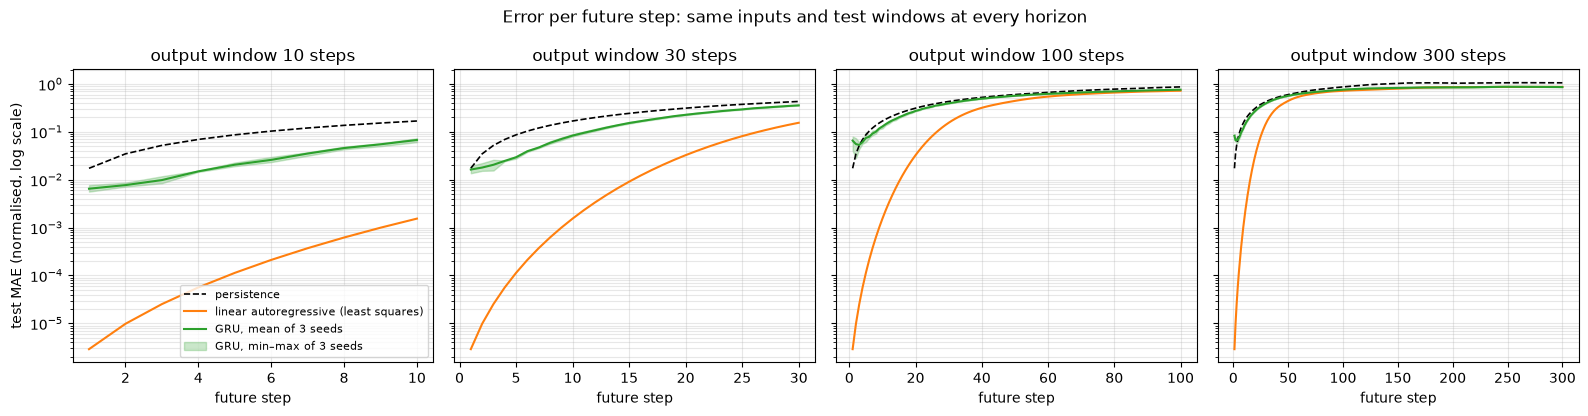

In [9]:
a_runs_df = pd.DataFrame(a_runs); a_steps_df = pd.DataFrame(a_steps)
a_runs_df.to_csv(RES / "a_gru_runs.csv", index=False); a_steps_df.to_csv(RES / "a_gru_by_step_runs.csv", index=False)
gru_step = a_steps_df.groupby(["horizon", "step"]).mae.agg(["mean", "min", "max"]).reset_index()
gru_step.to_csv(RES / "a_gru_by_step_summary.csv", index=False)

rows = []
for h in HORIZONS:
    g = a_runs_df[a_runs_df.horizon == h].test_mae
    lin = float(ref_window[(ref_window.model == "linear AR") & (ref_window.horizon == h)].mae.iloc[0])
    per = float(ref_window[(ref_window.model == "persistence") & (ref_window.horizon == h)].mae.iloc[0])
    rows.append(dict(horizon=h, persistence=per, linear_AR=lin, gru_mean=g.mean(), gru_min=g.min(), gru_max=g.max(), gru_range=g.max() - g.min(),
                     gru_over_linear=g.mean() / lin, gru_beats_linear=bool((g.max() < lin) and ((lin - g.mean()) > (g.max() - g.min()))),
                     gru_beats_persistence=bool((g.max() < per) and ((per - g.mean()) > (g.max() - g.min()))),
                     gru_epochs=a_runs_df[a_runs_df.horizon == h].epochs.tolist(), gru_train_s_mean=a_runs_df[a_runs_df.horizon == h].train_s.mean()))
a_table = pd.DataFrame(rows); a_table.to_csv(RES / "a_window_table.csv", index=False)
print("Test MAE over the window (normalised units); GRU as mean and [min, max] of seeds 0, 1, 2")
print(a_table.drop(columns=["gru_epochs"]).round(5).to_string(index=False))
first = a_table[a_table.gru_beats_linear]
print("\nResult (a):", f"the GRU first beats the linear model beyond its seed range at horizon {int(first.horizon.iloc[0])}" if len(first)
      else "the GRU does not beat the linear model beyond its seed range at any of the four horizons")
print("GRU / linear AR error ratio by horizon:", ", ".join(f"h={int(r.horizon)}: {r.gru_over_linear:.1f}×" for r in a_table.itertuples()))

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
for ax, h in zip(axes, HORIZONS):
    s = np.arange(1, h + 1)
    ax.plot(s, ref_steps[(ref_steps.model == "persistence") & (ref_steps.step <= h)].mae, "k--", lw=1.2, label="persistence")
    ax.plot(s, ref_steps[(ref_steps.model == "linear AR") & (ref_steps.step <= h)].mae, color="#ff7f0e", lw=1.5, label="linear autoregressive (least squares)")
    g = gru_step[gru_step.horizon == h]
    ax.plot(g.step, g["mean"], color="#2ca02c", lw=1.5, label="GRU, mean of 3 seeds"); ax.fill_between(g.step, g["min"], g["max"], color="#2ca02c", alpha=0.25, label="GRU, min–max of 3 seeds")
    ax.set_yscale("log"); ax.set_title(f"output window {h} steps"); ax.set_xlabel("future step"); ax.grid(alpha=0.3, which="both")
axes[0].set_ylabel("test MAE (normalised, log scale)"); axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Error per future step: same inputs and test windows at every horizon"); fig.tight_layout(); fig.savefig(RES / "a_error_by_step.png", dpi=130); plt.show()

## Part (b): the Transformer with a training budget it can use

The Transformer of Stage 3 (d_model 32, 4 heads, feed-forward 64, 2 encoder blocks, dropout 0.1, 10 outputs), with its builder copied unchanged below (positional embedding, encoder block and model function from that stage). Two settings, three seeds each, on the horizon-10 targets of this notebook's windows, so the comparison with the GRU of part (a) is on identical windows:

- **Earlier setting**: Adam at 1e-4 with gradient clipping 1, 50 epochs, early stopping patience 8 and learning-rate halving after 4 epochs without improvement, as in Stages 3 and 4 (where it never stopped early).
- **Tuned setting**: Adam at 1e-3 with gradient clipping 1, early stopping patience 8 (best weights restored), up to 100 epochs, no learning-rate schedule — the budget the recurrent networks had.

In [10]:
# Copied unchanged from Stage 3 (positional embedding, encoder block, model builder)

class PositionalEmbedding(tf.keras.layers.Layer):
    """Adds trainable positional information to the input sequence."""
    def __init__(self, sequence_length, d_model):
        super().__init__()
        self.sequence_length = sequence_length
        self.d_model = d_model
        self.position_embedding = tf.keras.layers.Embedding(input_dim=sequence_length, output_dim=d_model)
    def call(self, inputs):
        positions = tf.range(start=0, limit=tf.shape(inputs)[1], delta=1)
        positions = self.position_embedding(positions)
        return inputs + positions
    def get_config(self):
        config = super().get_config(); config.update({"sequence_length": self.sequence_length, "d_model": self.d_model}); return config

def transformer_encoder_block(x, d_model=32, num_heads=4, ff_dim=64, dropout_rate=0.1):
    """Multi-head self-attention, residual + layer normalisation, feed-forward, residual + layer normalisation."""
    attention_output = tf.keras.layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model // num_heads)(x, x)
    attention_output = tf.keras.layers.Dropout(dropout_rate)(attention_output)
    x = tf.keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)
    ff_output = tf.keras.layers.Dense(ff_dim, activation="relu")(x)
    ff_output = tf.keras.layers.Dense(d_model)(ff_output)
    ff_output = tf.keras.layers.Dropout(dropout_rate)(ff_output)
    x = tf.keras.layers.LayerNormalization(epsilon=1e-6)(x + ff_output)
    return x

def create_simple_transformer(window_size, output_window, d_model=32, num_heads=4, ff_dim=64, num_blocks=2, dropout_rate=0.1, learning_rate=1e-4):
    """Input (samples, window_size, 1) → output (samples, output_window)."""
    inputs = tf.keras.layers.Input(shape=(window_size, 1))
    x = tf.keras.layers.Dense(d_model)(inputs)
    x = PositionalEmbedding(sequence_length=window_size, d_model=d_model)(x)
    for _ in range(num_blocks):
        x = transformer_encoder_block(x, d_model=d_model, num_heads=num_heads, ff_dim=ff_dim, dropout_rate=dropout_rate)
    last_token = tf.keras.layers.Lambda(lambda z: z[:, -1, :])(x)
    global_summary = tf.keras.layers.GlobalAveragePooling1D()(x)
    x = tf.keras.layers.Concatenate()([last_token, global_summary])
    x = tf.keras.layers.Dense(64, activation="relu")(x)
    x = tf.keras.layers.Dropout(dropout_rate)(x)
    outputs = tf.keras.layers.Dense(output_window)(x)
    model = tf.keras.Model(inputs=inputs, outputs=outputs, name="Simple_Transformer_Forecaster")
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate, clipnorm=1.0), loss="mse", metrics=["mae"])
    return model

SETTINGS = {
    "Transformer, earlier setting (1e-4, 50 epochs)": dict(lr=1e-4, epochs=50, callbacks=lambda: [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6)]),
    "Transformer, tuned (1e-3, up to 100 epochs)": dict(lr=1e-3, epochs=100, callbacks=lambda: [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)]),
}
b_runs, b_steps = [], []
def run_transformer_seed(seed):
    for name, cfg in SETTINGS.items():
        tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
        m = create_simple_transformer(window_size=300, output_window=10, learning_rate=cfg["lr"])
        hist, train_s, p = fit_model(m, ytr[:, :10], yva[:, :10], seed, cfg["epochs"], cfg["callbacks"](), NET_DEVICE["Simple Transformer"])
        e = mae_steps(yte[:, :10], p); r = rmse_steps(yte[:, :10], p)
        b_runs.append(dict(model=name, seed=seed, device=NET_DEVICE["Simple Transformer"], params=m.count_params(), epochs=len(hist.history["loss"]),
                           best_epoch=int(np.argmin(hist.history["val_loss"])) + 1, train_s=round(train_s, 1), test_mae=float(e.mean()), test_rmse=float(np.sqrt((r ** 2).mean()))))
        b_steps.extend(dict(model=name, seed=seed, step=s + 1, mae=float(e[s]), rmse=float(r[s])) for s in range(10))
        if seed == 0: m.save(MOD / ("Transformer_" + ("tuned" if cfg["lr"] == 1e-3 else "earlier_setting") + "_seed0.keras"))
        print(b_runs[-1], flush=True)

In [11]:
run_transformer_seed(0)  # seed 0, the base run

{'model': 'Transformer, earlier setting (1e-4, 50 epochs)', 'seed': 0, 'device': '/GPU:0', 'params': 31562, 'epochs': 50, 'best_epoch': 47, 'train_s': 132.0, 'test_mae': 0.10307099670171738, 'test_rmse': 0.15865615010261536}


{'model': 'Transformer, tuned (1e-3, up to 100 epochs)', 'seed': 0, 'device': '/GPU:0', 'params': 31562, 'epochs': 75, 'best_epoch': 67, 'train_s': 204.3, 'test_mae': 0.05553935095667839, 'test_rmse': 0.09345974773168564}


In [12]:
run_transformer_seed(1)  # seed 1

{'model': 'Transformer, earlier setting (1e-4, 50 epochs)', 'seed': 1, 'device': '/GPU:0', 'params': 31562, 'epochs': 50, 'best_epoch': 50, 'train_s': 141.3, 'test_mae': 0.10223107039928436, 'test_rmse': 0.15967035293579102}


{'model': 'Transformer, tuned (1e-3, up to 100 epochs)', 'seed': 1, 'device': '/GPU:0', 'params': 31562, 'epochs': 52, 'best_epoch': 44, 'train_s': 147.1, 'test_mae': 0.06740351766347885, 'test_rmse': 0.10529311746358871}


In [13]:
run_transformer_seed(2)  # seed 2

{'model': 'Transformer, earlier setting (1e-4, 50 epochs)', 'seed': 2, 'device': '/GPU:0', 'params': 31562, 'epochs': 50, 'best_epoch': 46, 'train_s': 143.7, 'test_mae': 0.10619346052408218, 'test_rmse': 0.1641147881746292}


{'model': 'Transformer, tuned (1e-3, up to 100 epochs)', 'seed': 2, 'device': '/GPU:0', 'params': 31562, 'epochs': 45, 'best_epoch': 37, 'train_s': 129.9, 'test_mae': 0.0701824277639389, 'test_rmse': 0.10880467295646667}


### Part (b) table and figure

All rows at horizon 10 on this notebook's test windows. A model beats a reference only when all three seeds are below it and the mean gain is larger than the seed range. "Reaches the GRU" means its seed range overlaps or lies below the GRU's. The last columns give Stage 4's numbers for the same models on its own (more numerous) windows, as an earlier run for orientation, not as the same test set.

Horizon 10, test MAE over the 10 steps (normalised units); networks as mean and [min, max] of seeds 0, 1, 2
                                         model  params  train_s_mean  mae_mean  mae_min  mae_max  seed_range beats_persistence beats_linear reaches_gru  earlier_run_mae_mean  earlier_run_mae_min  earlier_run_mae_max
                                   persistence       0       0.00000   0.09413      NaN      NaN         NaN               NaN          NaN         NaN               0.10278                  NaN                  NaN
                     linear AR (least squares)    3010       0.04800   0.00039      NaN      NaN         NaN               NaN          NaN         NaN               0.00040                  NaN                  NaN
                      GRU (part a, horizon 10)    3690      72.46667   0.02891  0.02677  0.03067     0.00390              True        False        True               0.03069              0.02877              0.03166
Transformer, earlier setting

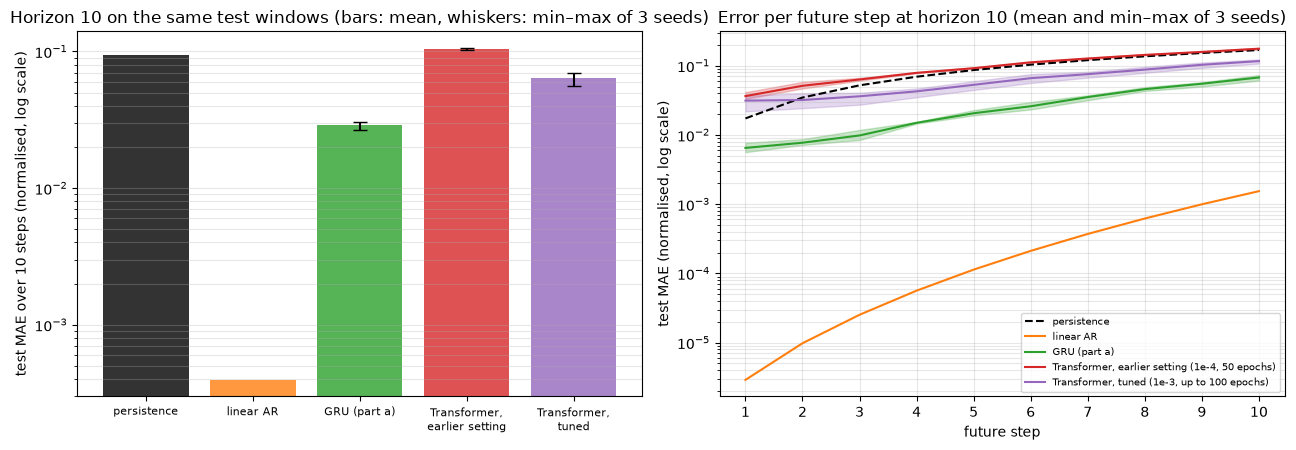

In [14]:
b_runs_df = pd.DataFrame(b_runs); b_steps_df = pd.DataFrame(b_steps)
b_runs_df.to_csv(RES / "b_transformer_runs.csv", index=False); b_steps_df.to_csv(RES / "b_transformer_by_step_runs.csv", index=False)
pd.concat([a_runs_df.assign(part="a"), b_runs_df.assign(part="b", horizon=10)]).to_csv(RES / "runs.csv", index=False)

lin10 = float(ref_window[(ref_window.model == "linear AR") & (ref_window.horizon == 10)].mae.iloc[0])
per10 = float(ref_window[(ref_window.model == "persistence") & (ref_window.horizon == 10)].mae.iloc[0])
gru10 = a_runs_df[a_runs_df.horizon == 10].test_mae
def summ(name, s, params, train_s):
    return dict(model=name, params=params, train_s_mean=train_s, mae_mean=s.mean(), mae_min=s.min(), mae_max=s.max(), seed_range=s.max() - s.min(),
                beats_persistence=bool((s.max() < per10) and ((per10 - s.mean()) > (s.max() - s.min()))),
                beats_linear=bool((s.max() < lin10) and ((lin10 - s.mean()) > (s.max() - s.min()))),
                reaches_gru=bool(s.min() <= gru10.max()))
b_rows = [dict(model="persistence", params=0, train_s_mean=0.0, mae_mean=per10), dict(model="linear AR (least squares)", params=int(W_all.shape[0] * 10), train_s_mean=round(lin_fit_s, 3), mae_mean=lin10),
          summ("GRU (part a, horizon 10)", gru10, int(a_runs_df[a_runs_df.horizon == 10].params.iloc[0]), a_runs_df[a_runs_df.horizon == 10].train_s.mean())]
for name in SETTINGS:
    r = b_runs_df[b_runs_df.model == name]
    b_rows.append(summ(name, r.test_mae, int(r.params.iloc[0]), r.train_s.mean()))
b_table = pd.DataFrame(b_rows)

# Earlier run (horizon-and-baselines stage, its own 7,419 windows), for orientation
try:
    earlier_b = pd.read_csv(EARLIER_STAGE / "b_cost_vs_error.csv", index_col=0)
    map_earlier = {"persistence": "persistence", "linear AR (least squares)": "linear AR (least squares)", "GRU (part a, horizon 10)": "GRU",
                   "Transformer, earlier setting (1e-4, 50 epochs)": "Simple Transformer"}
    b_table["earlier_run_mae_mean"] = [earlier_b.loc[map_earlier[m], "test_mae_mean"] if m in map_earlier else np.nan for m in b_table.model]
    b_table["earlier_run_mae_min"] = [earlier_b.loc[map_earlier[m], "test_mae_min"] if m in map_earlier else np.nan for m in b_table.model]
    b_table["earlier_run_mae_max"] = [earlier_b.loc[map_earlier[m], "test_mae_max"] if m in map_earlier else np.nan for m in b_table.model]
except FileNotFoundError:
    print("earlier-stage table not found; the comparison columns are left empty")
b_table.to_csv(RES / "b_table.csv", index=False)
print("Horizon 10, test MAE over the 10 steps (normalised units); networks as mean and [min, max] of seeds 0, 1, 2")
print(b_table.round(5).to_string(index=False))
tuned = b_table[b_table.model.str.contains("tuned")].iloc[0]; earl = b_table[b_table.model.str.contains("earlier setting")].iloc[0]
print(f"\nResult (b): tuned Transformer {tuned.mae_mean:.4f} [{tuned.mae_min:.4f}, {tuned.mae_max:.4f}] vs earlier setting {earl.mae_mean:.4f} [{earl.mae_min:.4f}, {earl.mae_max:.4f}]; "
      f"persistence {per10:.4f}; GRU {gru10.mean():.4f} [{gru10.min():.4f}, {gru10.max():.4f}]; linear AR {lin10:.5f}")
print(f"tuned Transformer beats persistence beyond the seed range: {tuned.beats_persistence}; reaches the GRU's seed range: {tuned.reaches_gru}; "
      f"beats the linear model: {tuned.beats_linear}; epochs per seed {b_runs_df[b_runs_df.model.str.contains('tuned')].epochs.tolist()} (best {b_runs_df[b_runs_df.model.str.contains('tuned')].best_epoch.tolist()})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
labels = ["persistence", "linear AR", "GRU (part a)", "Transformer,\nearlier setting", "Transformer,\ntuned"]
colors = ["k", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]
for i, (r, c) in enumerate(zip(b_table.itertuples(), colors)):
    if np.isnan(getattr(r, "mae_min", np.nan)): ax.bar(i, r.mae_mean, color=c, alpha=0.8)
    else: ax.bar(i, r.mae_mean, color=c, alpha=0.8, yerr=[[r.mae_mean - r.mae_min], [r.mae_max - r.mae_mean]], capsize=5)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=8); ax.set_yscale("log"); ax.set_ylabel("test MAE over 10 steps (normalised, log scale)")
ax.set_title("Horizon 10 on the same test windows (bars: mean, whiskers: min–max of 3 seeds)"); ax.grid(alpha=0.3, axis="y", which="both")
ax = axes[1]
s = np.arange(1, 11)
ax.plot(s, ref_steps[(ref_steps.model == "persistence") & (ref_steps.step <= 10)].mae, "k--", label="persistence")
ax.plot(s, ref_steps[(ref_steps.model == "linear AR") & (ref_steps.step <= 10)].mae, color="#ff7f0e", label="linear AR")
g = gru_step[gru_step.horizon == 10]; ax.plot(g.step, g["mean"], color="#2ca02c", label="GRU (part a)"); ax.fill_between(g.step, g["min"], g["max"], color="#2ca02c", alpha=0.25)
for name, c in zip(SETTINGS, ("#d62728", "#9467bd")):
    t = b_steps_df[b_steps_df.model == name].groupby("step").mae.agg(["mean", "min", "max"])
    ax.plot(t.index, t["mean"], color=c, label=name); ax.fill_between(t.index, t["min"], t["max"], color=c, alpha=0.25)
ax.set_yscale("log"); ax.set_xlabel("future step"); ax.set_ylabel("test MAE (normalised, log scale)"); ax.set_xticks(s); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=7)
ax.set_title("Error per future step at horizon 10 (mean and min–max of 3 seeds)")
fig.tight_layout(); fig.savefig(RES / "b_tuned_transformer.png", dpi=130); plt.show()

## Record of the run

In [15]:
summary = dict(windows=dict(train=int(len(Xtr)), val=int(len(Xva)), test=int(len(Xte)), input=300, output_max=H_MAX, stride=10),
               normalisation=dict(mean=MU, std=SIGMA, source="training inputs of Stages 2–4's windows"),
               persistence_check_horizon10_earlier_windows=pers_earlier, linear_fit_s=lin_fit_s, horizons=list(HORIZONS),
               part_a=a_table.drop(columns=["gru_epochs"]).to_dict("records"), part_b=b_table.to_dict("records"),
               longest_training_s=float(max(a_runs_df.train_s.max(), b_runs_df.train_s.max())), wall_s=round(time.time() - T_START, 1), devices=NET_DEVICE,
               tensorflow=tf.__version__, keras=tf.keras.__version__)
json.dump(summary, open(RES / "run_summary.json", "w"), indent=1, default=float)
print(f"longest single training {summary['longest_training_s']:.0f} s; notebook wall time {summary['wall_s'] / 60:.1f} min")

longest single training 204 s; notebook wall time 25.3 min
